# 16 — Mining the recursion direction (Schut §4.1.1 style)

Goal: extract a linear direction $v_\ell$ in residual-stream space such that, **before any body token is generated**, hidden states at positions in the `def`-through-end-of-docstring span separate tasks where greedy decoding ultimately produces recursion from tasks where it produces iteration.

**Setup:**
- **C** = "going to implement recursion" (dynamic concept; unrolls over future tokens)
- **D+** = tasks where `prompt_bias == "neutral"` AND `greedy.strategy == "recursive"` (greedy → recursion under a neutral prompt)
- **D-** = tasks where `prompt_bias == "neutral"` AND `greedy.strategy == "iterative"`
- **Span**: `def` token through closing `"""` of the docstring (inclusive). Strictly pre-body — any direction found here is a *proactiveness* signal by construction.
- **Constraint form**: Schut Eq. 2 — `min ||v||_1  s.t.  v·z+ ≥ v·z-` for many `(d+, t+, d-, t-)` quadruples.
- **Caveats accepted for v0**: function-name / task-identity leakage is allowed (we mimic Schut §4.1.1 looseness). To be revisited if overfitting shows up.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import sys
import json
import logging

import torch
import transformers

from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "1,2,3,4,6"

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, highlight=False)

def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)

logging.basicConfig(
    level=logging.INFO,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)
logger = logging.getLogger(__name__)
logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(f"{transformers.__version__=}")

2026-06-04 12:41:43 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-06-04 12:41:43 __main__ INFO     transformers.__version__='5.3.0'


In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")

2026-06-04 12:41:47 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-06-04 12:41:47 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-04 12:41:47 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-06-04 12:41:47 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-04 12:41:47 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-06-04 12:41:47 httpx INFO     HTT

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-06-04 12:42:10 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-04 12:42:10 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-06-04 12:42:10 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40


## 1. Load greedy generations and build D+ / D-

Each JSON under `results/well-known-tasks/generations/<model>/<source>/` is one task. We keep only **neutral-bias** tasks and label each by `greedy.strategy`.

In [4]:
import json
from collections import Counter
from pathlib import Path

import pandas as pd

from src.utils import env_utils

RESULTS_DIR = Path(
    os.path.join(
        env_utils.DEFAULT_RESULTS_DIR,
        "well-known-tasks/generations",
        mt.name.split("/")[-1],
    )
)

records = []
for src_dir in sorted(p for p in RESULTS_DIR.iterdir() if p.is_dir()):
    for fp in sorted(src_dir.glob("*.json")):
        with open(fp) as f:
            records.append(json.load(f))

print(f"Loaded {len(records)} records from {RESULTS_DIR}")
print(f"Sources : {dict(Counter(r['source'] for r in records))}")
print(f"Bias    : {dict(Counter(r['prompt_bias'] for r in records))}")

Loaded 293 records from /disk/u/arnab/Codes/Projects/goals/results/well-known-tasks/generations/Qwen2.5-Coder-32B-Instruct
Sources : {'custom': 176, 'humaneval': 73, 'mbpp': 44}
Bias    : {'neutral': 284, 'recursive': 4, 'iterative': 5}


In [5]:
# D+ / D- by greedy strategy under neutral prompts only
D_plus  = [r for r in records if r["prompt_bias"] == "neutral" and r["greedy"]["strategy"] == "recursive"]
D_minus = [r for r in records if r["prompt_bias"] == "neutral" and r["greedy"]["strategy"] == "iterative"]

print(f"|D+| = {len(D_plus)}  (greedy proactively chose recursion)")
print(f"|D-| = {len(D_minus)} (greedy proactively chose iteration)")

# Quick eyeball of which tasks ended up in each pool
print("\nD+ sample functions:", [r["function_name"] for r in D_plus[:10]])
print("D- sample functions:", [r["function_name"] for r in D_minus[:10]])

|D+| = 29  (greedy proactively chose recursion)
|D-| = 188 (greedy proactively chose iteration)

D+ sample functions: ['ackermann', 'combinations', 'count_and_say', 'count_leaves', 'count_tree_nodes', 'factorial', 'flatten_nested_list', 'invert_binary_tree', 'is_subtree', 'josephus_problem']
D- sample functions: ['add_binary', 'add_two_numbers_linked_list', 'add_without_plus', 'atoi', 'basic_calculator', 'bellman_ford', 'bfs', 'binary_search', 'binary_search_leftmost', 'binary_search_rightmost']


## 2. Span extraction (`def` → closing `"""`)

Find the substring from the first `def ` through the closing `"""` of the docstring, then resolve to a `(start, end)` token range via `find_token_range`.

In [6]:
from src.tokens import find_token_range, prepare_input


def get_span_token_range(record, mt) -> tuple[int, int] | None:
    """(start_token, end_token) inclusive-exclusive for the def→docstring span."""
    prompt = record["prompt"]
    gen = record["greedy"]["extracted_code"]
    full_prompt = prompt + gen

    # print(full_prompt)

    tokenized = prepare_input(
        prompts=full_prompt, tokenizer=mt, return_offsets_mapping=True
    )
    offsets = tokenized.pop("offset_mapping")[0]

    try:
        code_start, _ = find_token_range(
            string=full_prompt, substring="<code>", occurrence=1, tokenizer=mt, offset_mapping=offsets
        )
    except ValueError:
        logger.error(
            f"couldn't find 'def' in the full prompt for function {record['function_name']}"
        )
        return None

    try:
        _, docstring_end = find_token_range(
            string=full_prompt,
            substring='"""',
            tokenizer=mt,
            offset_mapping=offsets,
            occurrence=1,
        )
        # token_span = (def_start, docstring_end)
        # print(
        #     f"{token_span=}: {[mt.tokenizer.decode(t) for t in tokenized.input_ids[0][def_start:docstring_end]]}"
        # )
        return code_start, docstring_end
    except ValueError:
        logger.error(
            f"error parsing docstring in full prompt for function {record['function_name']}"
        )
        return (
            code_start,
            code_start + 5,
        )  # fallback with a reasonable guess for the span end


# Test on one D+ sample
r = D_plus[0]
span = get_span_token_range(r, mt)
print(
    f"task={r['function_name']:<25s} span_tokens={span}  ({span[1] - span[0]} tokens)"
)

base_prompt = r["prompt"]
gen = r["greedy"]["extracted_code"]
full_prompt = base_prompt + gen

tokenized = prepare_input(prompts=full_prompt, tokenizer=mt)
ids = tokenized.input_ids[0].tolist()
decoded_span = [mt.tokenizer.decode([i]) for i in ids[span[0] : span[1]]]
rich_print(f"Tokens in span {span}:", decoded_span)
len(decoded_span)

task=ackermann                 span_tokens=(69, 86)  (17 tokens)


Tokens in span (69, 86):
[
    '\n',
    '<',
    'code',
    '>\n',
    'def',
    ' ack',
    'ermann',
    '(m',
    ',',
    ' n',
    '):\n',
    '   ',
    ' """',
    'Ack',
    'ermann',
    ' function',
    '"""\n'
]

17

In [7]:
import numpy as np

# Filter out records where span extraction fails, attach span to each record
def attach_spans(pool):
    kept = []
    for r in pool:
        span = get_span_token_range(r, mt)
        if span is None:
            continue
        r = dict(r)
        r["_span"] = span  # (start, end) token-index range (end exclusive)
        kept.append(r)
    return kept

D_plus  = attach_spans(D_plus)
D_minus = attach_spans(D_minus)
print(f"After span filtering: |D+|={len(D_plus)}  |D-|={len(D_minus)}")

# Span length distribution — useful sanity check
span_lens = [r["_span"][1] - r["_span"][0] for r in D_plus + D_minus]
print(f"Span length: min={min(span_lens)}  median={int(np.median(span_lens))}  max={max(span_lens)}")

After span filtering: |D+|=29  |D-|=188
Span length: min=12  median=23  max=108


In [8]:
small_spans = [r for r in D_plus + D_minus if (r["_span"][1] - r["_span"][0]) <= 12]
# small_spans[0]

In [9]:
for idx, r in enumerate(D_plus):
    print(f"{idx}: {r['function_name']}")

0: ackermann
1: combinations
2: count_and_say
3: count_leaves
4: count_tree_nodes
5: factorial
6: flatten_nested_list
7: invert_binary_tree
8: is_subtree
9: josephus_problem
10: lowest_common_ancestor
11: max_depth
12: merge_sort
13: merge_two_trees
14: path_sum
15: permutations
16: postorder_traversal
17: preorder_traversal
18: quick_sort
19: regular_expression_matching
20: same_tree
21: topological_sort_dfs
22: tower_of_hanoi
23: numerical_letter_grade
24: prime_length
25: div_sum
26: flatten_list
27: recursive_list_sum
28: str_to_list


In [10]:
len(D_plus), len(D_minus)

(29, 188)

In [11]:
from rich.markup import escape

r = D_plus[5]
prompt = r["prompt"]
gen = r["greedy"]["extracted_code"]
rich_print(f"[white]{escape(prompt)}[/white][sea_green3]{escape(gen)}[/sea_green3]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Implement factorial in Python. Write your code without any comments or explanations, just the 
implementation.<|im_end|>
<|im_start|>assistant
<code>
def factorial(n):
    """Calculate the factorial of a non-negative integer n."""
    if n == 0:
        return 1
    else:
        return n * factorial(n-1)
</code>

## 3. Extract hidden states across the span, all layers

For each task, one forward pass; slice the full hidden-state tensor at span positions. Store on CPU in fp16.

In [12]:
from tqdm.auto import tqdm
from src.functional import get_hs

@torch.no_grad()
def get_span_hidden_states(record, mt):
    """Return (n_layer, span_len, n_embd) on CPU in fp16.

    Uses `get_hs` from src.functional: one nnsight trace, fetches every
    (layer, position) pair in the span. Input is
        record['prompt'] + record['greedy']['extracted_code']
    because the closing `\"\"\"` lives in the extracted code; the `_span`
    indices stored on the record were computed against this combined string.

    Leading-dim convention: index `i` = output of `mt.layer_names[i]` (the
    i-th transformer block). Embedding output is NOT included — so layer
    indices here run 0..n_layer-1, unlike model.output_hidden_states which
    runs 0..n_layer (with index 0 = embedding).
    """
    input_text = record["prompt"] + record["greedy"]["extracted_code"]
    tokenized = prepare_input(prompts=input_text, tokenizer=mt)
    start, end = record["_span"]
    positions = list(range(start, end))
    layer_names = mt.layer_names
    locations = [(ly, t) for ly in layer_names for t in positions]
    hs_dict = get_hs(mt=mt, input=tokenized, locations=locations, return_dict=True)
    hs = torch.stack(
        [torch.stack([hs_dict[(ly, t)].detach().to('cpu') for t in positions], dim=0) for ly in layer_names],
        dim=0,
    )
    return hs.to("cpu", dtype=torch.float16)


# Cache hidden states for every task in D+ ∪ D-
for r in tqdm(D_plus,  desc="D+"):
    r["_hs"] = get_span_hidden_states(r, mt)
for r in tqdm(D_minus, desc="D-"):
    r["_hs"] = get_span_hidden_states(r, mt)

example_hs = D_plus[0]["_hs"]
print(f"per-task HS tensor: {tuple(example_hs.shape)}  dtype={example_hs.dtype}")


D+:   0%|          | 0/29 [00:00<?, ?it/s]

D-:   0%|          | 0/188 [00:00<?, ?it/s]

per-task HS tensor: (64, 17, 5120)  dtype=torch.float16


## 4. Train / test split by task + constraint sampling

Hold out whole tasks (not individual positions). Sample up to `TRAIN_LIMIT` quadruples `(d+, t+, d-, t-)` for the optimizer.

In [13]:
import random

SEED = 0
TEST_FRAC = 0.2
TRAIN_LIMIT = 10_000  # max constraints fed into the optimizer

rng = random.Random(SEED)

def split_by_task(pool, test_frac, rng):
    idx = list(range(len(pool)))
    rng.shuffle(idx)
    n_test = max(1, int(len(idx) * test_frac))
    test_ix = set(idx[:n_test])
    train = [pool[i] for i in range(len(pool)) if i not in test_ix]
    test  = [pool[i] for i in range(len(pool)) if i     in test_ix]
    return train, test

D_plus_train,  D_plus_test  = split_by_task(D_plus,  TEST_FRAC, rng)
D_minus_train, D_minus_test = split_by_task(D_minus, TEST_FRAC, rng)

print(f"train:  |D+|={len(D_plus_train)}  |D-|={len(D_minus_train)}")
print(f"test :  |D+|={len(D_plus_test)}   |D-|={len(D_minus_test)}")


def sample_constraints(D_pos, D_neg, train_limit, rng):
    """Random quadruples (i, t+, j, t-) — sample, position, sample, position."""
    quads = []
    n_pos, n_neg = len(D_pos), len(D_neg)
    while len(quads) < train_limit:
        i = rng.randrange(n_pos)
        j = rng.randrange(n_neg)
        T_plus  = D_pos[i]["_hs"].shape[1]
        T_minus = D_neg[j]["_hs"].shape[1]
        tp = rng.randrange(T_plus)
        tm = rng.randrange(T_minus)
        quads.append((i, tp, j, tm))
    return quads

train_quads = sample_constraints(D_plus_train, D_minus_train, TRAIN_LIMIT, rng)
print(f"Sampled {len(train_quads)} training constraints")

train:  |D+|=24  |D-|=151
test :  |D+|=5   |D-|=37
Sampled 10000 training constraints


## 5. Optimize direction $v_\ell$ (Schut Eq. 2, hinge-loss, unit-norm)

We modify Schut's exact formulation in two ways:

- **Drop the L1 sparsity term.** L1 prefers basis-aligned directions; we have no reason to expect "going to implement recursion" to align with model bases.
- **Unit-normalize latents and the direction.** All $z^+, z^-$ are L2-normalized per position before training/eval, and we optimize over the unit sphere ($\|v\|=1$). We care about the *direction*, not magnitudes.

Loss (relaxed hinge over the unit sphere):
$$\mathcal{L}(v) = \frac{1}{N}\sum_{(i,t,j,s)} \max\!\Big(0,\, \text{margin} - \hat v \cdot (\hat z^+_{i,t} - \hat z^-_{j,s})\Big), \qquad \hat v = v / \|v\|.$$

Margin is in cosine-similarity scale now, so a much smaller value (~0.05–0.2) is appropriate.

In [14]:
def stack_at_layer(pool, layer_idx, normalize: bool = True):
    """List of (T_i, d) tensors at *layer_idx*, optionally L2-normalized per position.

    Default is `normalize=True`: each position-row has unit L2 norm. This is
    the convention used throughout training, evaluation, and visualization in
    this notebook — we mine direction, not magnitude.
    """
    out = []
    for r in pool:
        h = r["_hs"][layer_idx].to(torch.float32)
        if normalize:
            h = h / (h.norm(dim=-1, keepdim=True) + 1e-9)
        out.append(h)
    return out


def optimize_direction(
    pos_hs_list,   # list of (T_i, d) tensors — pre-normalized
    neg_hs_list,
    quads,         # list of (i, t+, j, t-)
    *,
    margin: float = 0.1,
    lr: float = 1e-2,
    n_steps: int = 2000,
    batch_size: int = 1024,
    seed: int = 0,
    device: str = "cuda",
    verbose: bool = True,
    random_init: bool = False,
):
    """Optimize a unit direction v on the sphere via hinge loss.

    We parameterize the free vector and normalize inside the forward pass
    (``v_unit = v / ||v||``); the returned vector is unit-norm on CPU.

    Initialization:
      - random_init=False (default): warm-start from mean(Z+) - mean(Z-).
        Faster convergence for real runs but, on shuffled-label controls,
        the warm start can carry leaked class signal whenever the random
        train split is class-imbalanced.
      - random_init=True: initialize v as a random unit vector seeded by
        `seed`. Use this for the sanity-check / shuffled-label run.

    Returns (v_unit on CPU, history dict).
    """
    d = pos_hs_list[0].shape[-1]

    # Pre-stack the (z+, z-) pairs for all constraints (faster than indexing per step)
    Zp = torch.stack([pos_hs_list[i][tp] for (i, tp, _, _) in quads]).to(device)
    Zn = torch.stack([neg_hs_list[j][tm] for (_, _, j, tm) in quads]).to(device)
    diffs = (Zp - Zn).contiguous()  # (N, d)
    N = diffs.shape[0]

    if random_init:
        g = torch.Generator(device=device).manual_seed(seed)
        init = torch.randn(d, generator=g, device=device)
    else:
        init = Zp.mean(dim=0) - Zn.mean(dim=0)
    v = (init / (init.norm() + 1e-9)).clone().detach().requires_grad_(True)
    opt = torch.optim.Adam([v], lr=lr)

    hist = {"loss": [], "sat": []}
    for step in range(n_steps):
        idx = torch.randint(0, N, (batch_size,), device=device)
        b = diffs[idx]                                  # (B, d)
        v_unit = v / (v.norm() + 1e-9)
        margins_b = (b * v_unit).sum(dim=-1)            # (B,)
        loss = torch.clamp(margin - margins_b, min=0).mean()

        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()

        if step % max(1, n_steps // 20) == 0 or step == n_steps - 1:
            with torch.no_grad():
                v_u_full = v / (v.norm() + 1e-9)
                full_margins = (diffs * v_u_full).sum(dim=-1)
                sat = (full_margins > 0).float().mean().item()
            hist["loss"].append(loss.item())
            hist["sat"].append(sat)
            if verbose:
                print(f"  step {step:5d}  loss={loss.item():.4f}  sat(train)={sat:.3f}")

    v_final = (v / (v.norm() + 1e-9)).detach().cpu()
    return v_final, hist


def mean_diff_direction(pos_hs_list, neg_hs_list):
    """Baseline: unit-normalize(mean(z+) - mean(z-)). Inputs are already unit-normalized."""
    pos_flat = torch.cat([h.reshape(-1, h.shape[-1]) for h in pos_hs_list], dim=0)
    neg_flat = torch.cat([h.reshape(-1, h.shape[-1]) for h in neg_hs_list], dim=0)
    diff = pos_flat.mean(dim=0) - neg_flat.mean(dim=0)
    return diff / (diff.norm() + 1e-9)


In [15]:
TARGET_LAYER = 44   # 0..n_layer-1 (output of mt.layer_names[TARGET_LAYER])
MARGIN       = 0.1  # cosine-similarity scale (latents are unit-normalized)
N_STEPS      = 200
LR           = 1e-2
BATCH_SIZE   = 1024

pos_hs = stack_at_layer(D_plus_train,  TARGET_LAYER)
neg_hs = stack_at_layer(D_minus_train, TARGET_LAYER)

v_opt, opt_hist = optimize_direction(
    pos_hs, neg_hs, train_quads,
    margin=MARGIN,
    lr=LR, n_steps=N_STEPS, batch_size=BATCH_SIZE,
)
v_md = mean_diff_direction(pos_hs, neg_hs)
print(f"v_opt  ||v||_2={v_opt.norm():.4f}   (should be 1.0)")
print(f"v_md   ||v||_2={v_md.norm():.4f}    (should be 1.0)")
print(f"cos(v_opt, v_md) = {(v_opt @ v_md).item():.3f}")


  step     0  loss=0.0540  sat(train)=0.832
  step    10  loss=0.0327  sat(train)=0.969
  step    20  loss=0.0315  sat(train)=0.953
  step    30  loss=0.0313  sat(train)=0.966
  step    40  loss=0.0300  sat(train)=0.957
  step    50  loss=0.0309  sat(train)=0.961
  step    60  loss=0.0281  sat(train)=0.963
  step    70  loss=0.0315  sat(train)=0.961
  step    80  loss=0.0286  sat(train)=0.961
  step    90  loss=0.0306  sat(train)=0.964
  step   100  loss=0.0293  sat(train)=0.959
  step   110  loss=0.0291  sat(train)=0.966
  step   120  loss=0.0297  sat(train)=0.962
  step   130  loss=0.0275  sat(train)=0.955
  step   140  loss=0.0289  sat(train)=0.965
  step   150  loss=0.0311  sat(train)=0.960
  step   160  loss=0.0293  sat(train)=0.959
  step   170  loss=0.0304  sat(train)=0.962
  step   180  loss=0.0296  sat(train)=0.963
  step   190  loss=0.0300  sat(train)=0.962
  step   199  loss=0.0286  sat(train)=0.956
v_opt  ||v||_2=1.0000   (should be 1.0)
v_md   ||v||_2=1.0000    (should be 

## 6. Detection accuracy on held-out tasks

Two views:
1. **Constraint satisfaction**: fraction of held-out `(d+, t+, d-, t-)` quadruples where `v·z+ > v·z-`.
2. **Per-position margin**: for each test sample, project all of its span positions onto v and average — does the resulting per-sample scalar separate D+ from D-?

In [16]:
TEST_QUADS_LIMIT = 4000

def constraint_satisfaction(v, D_pos, D_neg, layer_idx, n_quads, rng_seed=1):
    rng_local = random.Random(rng_seed)
    pos = stack_at_layer(D_pos, layer_idx)
    neg = stack_at_layer(D_neg, layer_idx)
    quads = sample_constraints(D_pos, D_neg, n_quads, rng_local)
    diffs = torch.stack([pos[i][tp] - neg[j][tm] for (i, tp, j, tm) in quads])
    margins = (diffs * v).sum(dim=-1)
    return (margins > 0).float().mean().item()


def per_sample_score(v, pool, layer_idx):
    """Mean projection of each sample's span-positions onto v → one scalar per task."""
    hs_list = stack_at_layer(pool, layer_idx)
    return torch.stack([(h * v).sum(dim=-1).mean() for h in hs_list])


for name, v in [("v_opt", v_opt), ("v_md", v_md)]:
    sat_tr = constraint_satisfaction(v, D_plus_train, D_minus_train, TARGET_LAYER, TEST_QUADS_LIMIT, rng_seed=2)
    sat_te = constraint_satisfaction(v, D_plus_test,  D_minus_test,  TARGET_LAYER, TEST_QUADS_LIMIT, rng_seed=3)
    scores_p = per_sample_score(v, D_plus_test,  TARGET_LAYER)
    scores_n = per_sample_score(v, D_minus_test, TARGET_LAYER)
    sep = (scores_p.mean() - scores_n.mean()).item() / (scores_p.std() + scores_n.std() + 1e-6).item()
    print(f"{name}: sat(train)={sat_tr:.3f}  sat(test)={sat_te:.3f}  per-sample sep_d-prime={sep:.2f}")

v_opt: sat(train)=0.950  sat(test)=0.919  per-sample sep_d-prime=1.50
v_md: sat(train)=0.727  sat(test)=0.711  per-sample sep_d-prime=0.87


## 7. Layer sweep

Sweep across `LAYERS_TO_SWEEP`; refit `v_opt` at each, report train/test satisfaction. Plot the curve.

In [17]:
# layer index `i` = output of mt.layer_names[i], so valid range is 0..n_layer-1
LAYERS_TO_SWEEP = sorted(list(set(list(range(0, mt.n_layer, 4)) + [mt.n_layer - 1])))

sweep_rows = []
for L in LAYERS_TO_SWEEP:
    pos_hs_L = stack_at_layer(D_plus_train,  L)
    neg_hs_L = stack_at_layer(D_minus_train, L)
    v_L, _ = optimize_direction(
        pos_hs_L, neg_hs_L, train_quads,
        margin=MARGIN,
        lr=LR, n_steps=N_STEPS, batch_size=BATCH_SIZE, verbose=False,
    )
    sat_tr = constraint_satisfaction(v_L, D_plus_train, D_minus_train, L, TEST_QUADS_LIMIT, rng_seed=2)
    sat_te = constraint_satisfaction(v_L, D_plus_test,  D_minus_test,  L, TEST_QUADS_LIMIT, rng_seed=3)
    sweep_rows.append({"layer": L, "sat_train": sat_tr, "sat_test": sat_te, "v": v_L})
    print(f"layer {L:2d}  sat_train={sat_tr:.3f}  sat_test={sat_te:.3f}")

sweep_df = pd.DataFrame([{k: v for k, v in r.items() if k != "v"} for r in sweep_rows])
sweep_df


layer  0  sat_train=0.744  sat_test=0.587
layer  4  sat_train=0.790  sat_test=0.609
layer  8  sat_train=0.846  sat_test=0.691
layer 12  sat_train=0.866  sat_test=0.717
layer 16  sat_train=0.927  sat_test=0.832
layer 20  sat_train=0.945  sat_test=0.825
layer 24  sat_train=0.956  sat_test=0.861
layer 28  sat_train=0.949  sat_test=0.842
layer 32  sat_train=0.953  sat_test=0.875
layer 36  sat_train=0.946  sat_test=0.879
layer 40  sat_train=0.963  sat_test=0.919
layer 44  sat_train=0.959  sat_test=0.930
layer 48  sat_train=0.987  sat_test=0.960
layer 52  sat_train=0.994  sat_test=0.964
layer 56  sat_train=0.997  sat_test=0.944
layer 60  sat_train=0.991  sat_test=0.937
layer 63  sat_train=0.979  sat_test=0.929


,layer,sat_train,sat_test
0,0,0.74400,0.58675
1,4,0.79050,0.60925
2,8,0.84650,0.69100
3,12,0.86625,0.71725
4,16,0.92675,0.83175
5,20,0.94475,0.82475
6,24,0.95625,0.86075
7,28,0.94875,0.84250
8,32,0.95350,0.87525
9,36,0.94625,0.87925


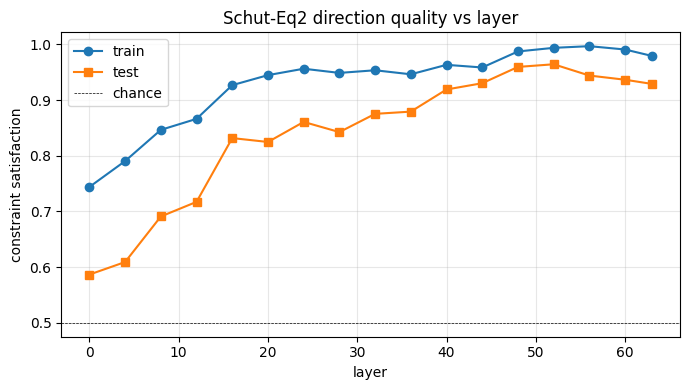

Best test layer: 52


In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep_df["layer"], sweep_df["sat_train"], "o-", label="train")
ax.plot(sweep_df["layer"], sweep_df["sat_test"],  "s-", label="test")
ax.axhline(0.5, color="k", lw=0.5, ls="--", label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("constraint satisfaction")
ax.set_title("Schut-Eq2 direction quality vs layer")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

BEST_LAYER = int(sweep_df.loc[sweep_df["sat_test"].idxmax(), "layer"])
print(f"Best test layer: {BEST_LAYER}")

## 8. Per-layer projection analysis (goal axis + residual PC1)

For each swept layer:
- **X-axis (goal)** = $z \cdot v_\ell$, projection of unit-normalized test positions onto the optimized direction $v_\ell$.
- **Y-axis (residual PC1)** = top principal component of $z - (z\cdot v)v$, i.e. variation orthogonal to the goal direction.

We report:
1. **AUC summary across layers** — separability of D+ vs D- along the goal axis and along the residual PC1. A clean goal direction shows high goal-axis AUC and near-chance residual-PC1 AUC.
2. **Animated scatter** — one frame per layer, so we can see when (and how cleanly) the direction crystallizes.

Adapted from `notebooks/03.1_multi_probe.ipynb` §"Contrastive Direction Projection".

 Layer  AUC(goal)  AUC(resid)
 -----  ---------  ----------
     0      0.593       0.521
     4      0.627       0.496
     8      0.690       0.499
    12      0.734       0.498
    16      0.836       0.497
    20      0.831       0.490
    24      0.864       0.497
    28      0.847       0.487
    32      0.881       0.483
    36      0.890       0.482
    40      0.918       0.477
    44      0.932       0.473
    48      0.957       0.473
    52      0.965       0.503
    56      0.946       0.523
    60      0.941       0.504
    63      0.930       0.525


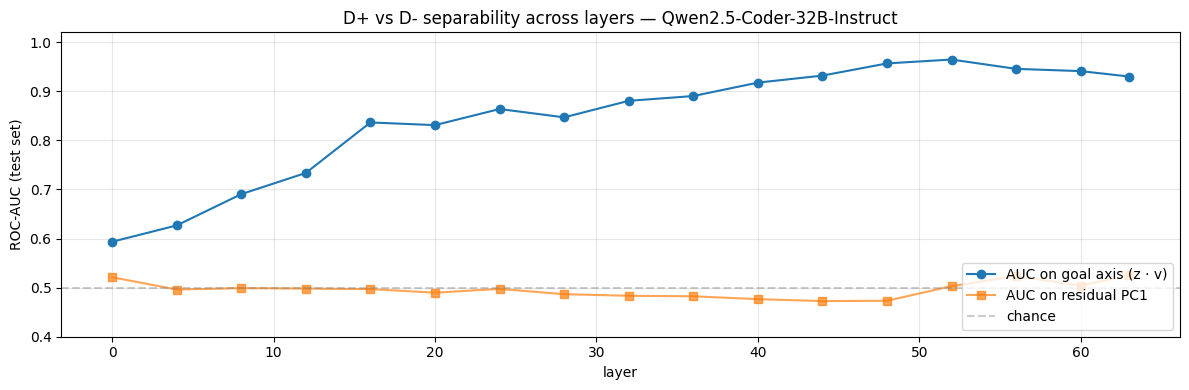

In [19]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score


def flatten_pool(pool, layer_idx, normalize: bool = True):
    """Concatenate every (sample, position) hidden state at *layer_idx*.

    With normalize=True (default), every row is unit-norm — matches the
    convention used in training/eval. We care about directions, not magnitudes.
    """
    rows = []
    for r in pool:
        h = r["_hs"][layer_idx].to(torch.float32).reshape(-1, mt.n_embd)
        if normalize:
            h = h / (h.norm(dim=-1, keepdim=True) + 1e-9)
        rows.append(h)
    return torch.cat(rows, dim=0)


# Per-layer goal + residual-PC1 projections using each layer's optimized v
proj_results: dict[int, dict] = {}
for row in sweep_rows:
    L = row["layer"]
    v = row["v"].numpy()
    z_pos = flatten_pool(D_plus_test,  L).numpy()
    z_neg = flatten_pool(D_minus_test, L).numpy()
    n_pos, n_neg = z_pos.shape[0], z_neg.shape[0]

    all_z = np.concatenate([z_pos, z_neg], axis=0)
    proj_goal = all_z @ v                                    # (N,)
    z_residual = all_z - np.outer(proj_goal, v)              # (N, d)
    proj_residual = PCA(n_components=1).fit_transform(z_residual).squeeze()

    labels = np.concatenate([np.ones(n_pos), np.zeros(n_neg)])
    proj_results[L] = {
        "pos_goal":     proj_goal[:n_pos],
        "neg_goal":     proj_goal[n_pos:],
        "pos_residual": proj_residual[:n_pos],
        "neg_residual": proj_residual[n_pos:],
        "auc_goal":     roc_auc_score(labels, proj_goal),
        "auc_residual": roc_auc_score(labels, proj_residual),
    }

print(f"{'Layer':>6} {'AUC(goal)':>10} {'AUC(resid)':>11}")
print(f"{'-----':>6} {'---------':>10} {'----------':>11}")
for L in sorted(proj_results):
    r = proj_results[L]
    print(f"{L:>6} {r['auc_goal']:>10.3f} {r['auc_residual']:>11.3f}")


# AUC summary across layers
layers_sorted   = sorted(proj_results)
auc_goal_vals   = [proj_results[L]["auc_goal"]     for L in layers_sorted]
auc_resid_vals  = [proj_results[L]["auc_residual"] for L in layers_sorted]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(layers_sorted, auc_goal_vals,  "o-", lw=1.5, label="AUC on goal axis (z · v)")
ax.plot(layers_sorted, auc_resid_vals, "s-", lw=1.5, alpha=0.7, label="AUC on residual PC1")
ax.axhline(0.5, color="gray", ls="--", alpha=0.4, label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("ROC-AUC (test set)")
ax.set_title(f"D+ vs D- separability across layers — {mt.name.split('/')[-1]}")
ax.legend(loc="lower right")
ax.set_ylim(0.4, 1.02)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


In [20]:
import matplotlib.animation as animation
from IPython.display import HTML

anim_layers = sorted(proj_results)

all_x = np.concatenate([np.concatenate([proj_results[L]["pos_goal"],     proj_results[L]["neg_goal"]])     for L in anim_layers])
all_y = np.concatenate([np.concatenate([proj_results[L]["pos_residual"], proj_results[L]["neg_residual"]]) for L in anim_layers])
pad_x = (all_x.max() - all_x.min()) * 0.05
pad_y = (all_y.max() - all_y.min()) * 0.05

fig, ax = plt.subplots(figsize=(8, 7))
neg_sc = ax.scatter([], [], alpha=0.3, s=12, c="tab:red",   label="D- (iterative)")
pos_sc = ax.scatter([], [], alpha=0.3, s=12, c="tab:green", label="D+ (recursive)")
ax.legend(markerscale=3, loc="upper left")
ax.set_xlim(all_x.min() - pad_x, all_x.max() + pad_x)
ax.set_ylim(all_y.min() - pad_y, all_y.max() + pad_y)
ax.axvline(0, color="gray", lw=0.5, ls="--", alpha=0.4)
ax.axhline(0, color="gray", lw=0.5, ls="--", alpha=0.4)
ax.set_xlabel("z · v   (goal axis)")
ax.set_ylabel("residual PC1   (z − (z·v)v)")
title = ax.set_title("")

def update(idx):
    L = anim_layers[idx]
    r = proj_results[L]
    pos_sc.set_offsets(np.column_stack([r["pos_goal"], r["pos_residual"]]))
    neg_sc.set_offsets(np.column_stack([r["neg_goal"], r["neg_residual"]]))
    title.set_text(
        f"Layer {L} | recursion direction | {mt.name.split('/')[-1]}\n"
        f"AUC(goal)={r['auc_goal']:.3f}  AUC(resid)={r['auc_residual']:.3f}"
    )
    return pos_sc, neg_sc, title

anim = animation.FuncAnimation(fig, update, frames=len(anim_layers), interval=400, blit=False)

# Save as .gif (pillow writer needs no external deps)
gif_dir = Path(env_utils.DEFAULT_RESULTS_DIR) / "recursion_direction" / mt.name.split("/")[-1] / "figures"
gif_dir.mkdir(parents=True, exist_ok=True)
gif_path = gif_dir / "goal_axis_residual_per_layer.gif"
anim.save(str(gif_path), writer="pillow", fps=2, dpi=120)
print(f"Saved {gif_path}")

plt.close(fig)
HTML(anim.to_jshtml())

2026-06-04 12:49:03 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.PillowWriter'>
Saved /disk/u/arnab/Codes/Projects/goals/results/recursion_direction/Qwen2.5-Coder-32B-Instruct/figures/goal_axis_residual_per_layer.gif
2026-06-04 12:49:06 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.HTMLWriter'>


## 9. Negative control — shuffled labels

Sanity floor: if we permute D+/D- labels, the optimizer should fail to find a direction. Anything not crushed by this control is suspicious.

In [21]:
import statistics

N_SHUFFLE_SEEDS = 10

sats = []
for seed in range(N_SHUFFLE_SEEDS):
    rng_shuf = random.Random(100 + seed)
    all_train = D_plus_train + D_minus_train
    rng_shuf.shuffle(all_train)
    half = len(all_train) // 2
    Dp_fake, Dn_fake = all_train[:half], all_train[half:]
    fake_quads = sample_constraints(Dp_fake, Dn_fake, TRAIN_LIMIT, rng_shuf)
    pos_fake = stack_at_layer(Dp_fake, BEST_LAYER)
    neg_fake = stack_at_layer(Dn_fake, BEST_LAYER)
    v_fake, _ = optimize_direction(
        pos_fake, neg_fake, fake_quads,
        margin=MARGIN, lr=LR, n_steps=N_STEPS, batch_size=BATCH_SIZE,
        random_init=True, seed=seed, verbose=False,
    )
    sat = constraint_satisfaction(
        v_fake, D_plus_test, D_minus_test, BEST_LAYER, TEST_QUADS_LIMIT, rng_seed=seed,
    )
    sats.append(sat)
    print(f"  seed {seed:2d}  sat_test={sat:.3f}")

print(
    f"\nshuffled-label sanity (layer {BEST_LAYER}, random init): "
    f"mean={statistics.mean(sats):.3f}  std={statistics.stdev(sats):.3f}  "
    f"min={min(sats):.3f}  max={max(sats):.3f}   (expect ~0.5)"
)


  seed  0  sat_test=0.699
  seed  1  sat_test=0.599
  seed  2  sat_test=0.719
  seed  3  sat_test=0.741
  seed  4  sat_test=0.306
  seed  5  sat_test=0.704
  seed  6  sat_test=0.602
  seed  7  sat_test=0.461
  seed  8  sat_test=0.607
  seed  9  sat_test=0.646

shuffled-label sanity (layer 52, random init): mean=0.608  std=0.134  min=0.306  max=0.741   (expect ~0.5)


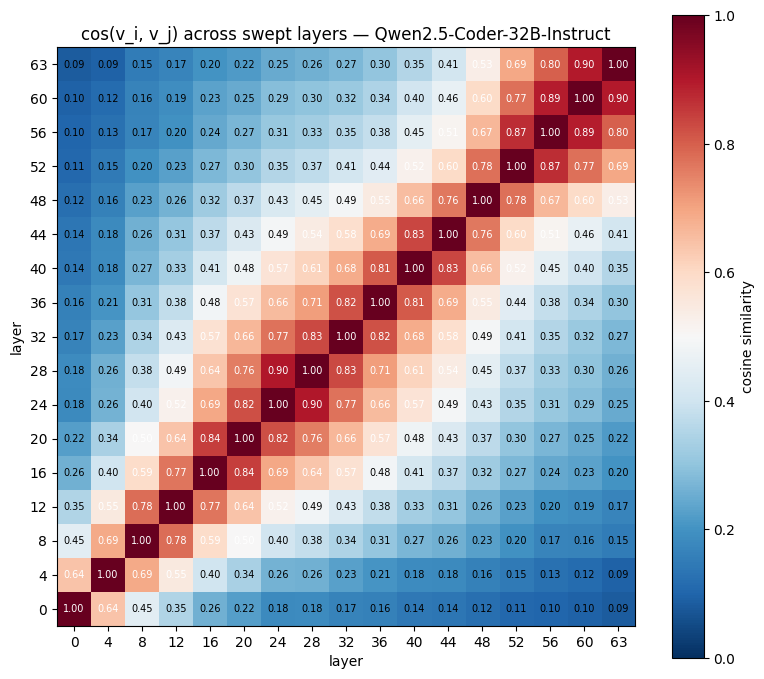

In [22]:
# Pairwise cosine similarity between v's across all swept layers.
# v's are already unit-norm (returned that way from optimize_direction), so
# V @ V.T is the cosine-similarity matrix directly.
import numpy as np

layers_sorted = sorted(r["layer"] for r in sweep_rows)
layer_to_v = {r["layer"]: r["v"] for r in sweep_rows}
V = torch.stack([layer_to_v[L] for L in layers_sorted], dim=0)  # (n_swept, d)
sim = (V @ V.T).numpy()                                        # (n_swept, n_swept)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(sim, cmap="RdBu_r", vmin=0, vmax=1, origin="lower")
ax.set_xticks(range(len(layers_sorted)))
ax.set_yticks(range(len(layers_sorted)))
ax.set_xticklabels(layers_sorted, rotation=0)
ax.set_yticklabels(layers_sorted)
ax.set_xlabel("layer")
ax.set_ylabel("layer")
ax.set_title(f"cos(v_i, v_j) across swept layers — {mt.name.split('/')[-1]}")
fig.colorbar(im, ax=ax, label="cosine similarity")

# Overlay numeric values when the matrix is small enough to be readable
n = len(layers_sorted)
if n <= 20:
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center",
                    color="white" if abs(sim[i, j]) > 0.5 else "black",
                    fontsize=7)

plt.tight_layout(); plt.show()


## 10. Causal validation

Once a credible direction is in hand:
- **Steering**: at a span position in a D- task, add $\alpha \cdot v$ to the residual stream across a range of layers and continue greedy decoding. Does the completion flip toward recursion?
- **Suppression**: at a span position in a D+ task, subtract $\alpha \cdot v$. Does the completion flip toward iteration?
- **Anticipatory profile** (§2.2 R-2 of `1_defining_goal.md`): sweep the steering position from early-span → late-span and plot flip rate as a function of $\delta$.

Decide the exact intervention (additive vs replace, layer range, $\alpha$ scan) once we see the v-quality curve from §7.

In [41]:
from src.goals.data import IncompleteCodeSample
from src.goals.functional import supports_chat_template, apply_chat_template
from src.goals.goalscope import greedy_continue
from rich.markup import escape


def get_prompt(sample, mt=mt):
    if supports_chat_template(mt):
        prompt = apply_chat_template(
            mt,
            user_query=sample.full_instruction.strip(),
            incomplete_code=sample.code,
        )
    else:
        prompt = sample.code
    return prompt


# OOD test pool — C++ tasks across various domains. Pushes the direction
# (mined on Python def→docstring spans) across the language gap, with a mix
# of tasks that naturally invite recursion and those that don't.
ood_samples = [
    IncompleteCodeSample(
        instruction="Write a C++ function that counts how many times a target value appears in a list of integers. Implement it from scratch without using built-in functions.",
        code="int count_occurrences(std::vector<int>& numbers, int target) {",
        unit_tests=[],
        function_name="count_occurrences",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that sorts a list of numbers in ascending order. Implement it from scratch without using built-in sorting functions.",
        code="void sort(std::vector<int>& numbers) {",
        unit_tests=[],
        function_name="sort",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that finds the greatest common divisor of two numbers. Implement it from scratch without using built-in functions.",
        code="int gcd(int x, int y) {",
        unit_tests=[],
        function_name="gcd",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that reverses the characters of a string in place. Implement it from scratch without using built-in functions.",
        code="void reverse_string(std::string& s) {",
        unit_tests=[],
        function_name="reverse_string",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that computes the sum of the decimal digits of a non-negative integer. Implement it from scratch without using built-in functions.",
        code="int sum_of_digits(int n) {",
        unit_tests=[],
        function_name="sum_of_digits",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that converts a non-negative integer to its binary representation as a string. Implement it from scratch without using built-in functions.",
        code="std::string decimal_to_binary(int n) {",
        unit_tests=[],
        function_name="decimal_to_binary",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that computes base raised to the power exp for non-negative integer exponents. Implement it from scratch without using built-in functions.",
        code="long long power(int base, int exp) {",
        unit_tests=[],
        function_name="power",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that checks whether a string reads the same forwards and backwards. Implement it from scratch without using built-in functions.",
        code="bool is_palindrome(const std::string& s) {",
        unit_tests=[],
        function_name="is_palindrome",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that finds the maximum value in a non-empty list of integers. Implement it from scratch without using built-in functions.",
        code="int find_max(std::vector<int>& numbers) {",
        unit_tests=[],
        function_name="find_max",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that reverses the digits of a non-negative integer. Implement it from scratch without using built-in functions.",
        code="int reverse_integer(int n) {",
        unit_tests=[],
        function_name="reverse_integer",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that checks whether a number is present in a list of integers sorted in ascending order. The time complexity should be O(log n). Implement it from scratch without using built-in functions.",
        code="bool search(std::vector<int>& numbers, int target) {",
        unit_tests=[],
        function_name="search",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that computes the factorial of a non-negative integer. Implement it from scratch without using built-in functions.",
        code="long long factorial(int n) {",
        unit_tests=[],
        function_name="factorial",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that computes the n-th Fibonacci number for a non-negative integer n. Implement it from scratch without using built-in functions.",
        code="long long fibonacci(int n) {",
        unit_tests=[],
        function_name="fibonacci",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that returns the sum of all integers in a list. Implement it from scratch without using built-in functions.",
        code="long long sum_array(std::vector<int>& numbers) {",
        unit_tests=[],
        function_name="sum_array",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that computes the length of a null-terminated C string. Implement it from scratch without using built-in functions.",
        code="int string_length(const char* s) {",
        unit_tests=[],
        function_name="string_length",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that returns the minimum value in a non-empty list of integers. Implement it from scratch without using built-in functions.",
        code="int find_min(std::vector<int>& numbers) {",
        unit_tests=[],
        function_name="find_min",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that multiplies two non-negative integers using only addition. Implement it from scratch without using built-in functions.",
        code="long long multiply(int a, int b) {",
        unit_tests=[],
        function_name="multiply",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that counts the number of digits in a non-negative integer. Implement it from scratch without using built-in functions.",
        code="int count_digits(int n) {",
        unit_tests=[],
        function_name="count_digits",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that checks whether a string starts with a lowercase character. Implement it from scratch without using built-in functions.",
        code="bool check(string str) {",
        unit_tests=[],
        function_name="check",
        prefills=[],
        augmentation=None,
    ),
    IncompleteCodeSample(
        instruction="Write a C++ function that gets the shortest distance between two nodes in a graph. Implement it from scratch without using built-in functions.",
        code="int bfs(vector<vector<int>>& graph, int start, int end) {",
        unit_tests=[],
        function_name="bfs",
        prefills=[],
        augmentation=None,
    ),
    
]
for s in ood_samples:
    s.without_comments = True


test_sample = ood_samples[-1]
test_prompt = get_prompt(test_sample, mt)

test_gen = greedy_continue(
    mt,
    **prepare_input(prompts=test_prompt, tokenizer=mt),
    max_new_tokens=256,
)
rich_print(f"[white]{escape(test_prompt)}[/white][sea_green3]{escape(test_gen)}[/sea_green3]")


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a C++ function that gets the shortest distance between two nodes in a graph. Implement it from scratch 
without using built-in functions. Write your code without any comments or explanations, just the 
implementation.<|im_end|>
<|im_start|>assistant
<code>
int bfs(vector<vector<int>>& graph, int start, int end) {  
    int n = graph.size();  
    vector<bool> visited(n, false);  
    vector<int> distance(n, 0);  
    queue<int> q;  
    q.push(start);  
    visited[start] = true;  
    while (!q.empty()) {  
        int u = q.front();  
        q.pop();  
        for (int v = 0; v < n; ++v) {  
            if (graph[u][v] == 1 && !visited[v]) {  
                visited[v] = true;  
                distance[v] = distance[u] + 1;  
                q.push(v);  
                if (v == end) return distance[v];  
            }  
        }  
    }  
    return -1;  
}
</code>

In [24]:
from src.functional import get_hs, PatchSpec, generate_with_patch

src_token_range = list(range(-5, 0))  # for normalization
src_hs = get_hs(
    mt=mt,
    input=test_prompt,
    locations=[(layer, t_idx) for layer in mt.layer_names for t_idx in src_token_range],
    return_dict=True,
)

layerwise_src_h_mean = {}
for layer in mt.layer_names:
    hs = torch.stack(
        [src_hs[(layer, t_idx)].to(torch.float32) for t_idx in src_token_range], dim=0
    )
    layerwise_src_h_mean[layer] = hs.mean(dim=0)  # (d,)

In [25]:
# from src.functional import logit_lens
# from baukit import get_module
# token = "recursive"
# token_id = mt.tokenizer(token, add_special_tokens=False)["input_ids"]
# lm_head = get_module(mt._model, mt.lm_head_name)
# row_tok = lm_head.weight[token_id]

# ll_res = logit_lens(
#     mt = mt,
#     h = row_tok,
#     k = 10
# )
# [str(ll) for ll in ll_res]

In [26]:
V_LAYER = 48
TARGET_LAYERS = list(range(35, 46))
ALPHA = 0.1


patches = []

for li in TARGET_LAYERS:
    src_h_mean = layerwise_src_h_mean[mt.layer_name_format.format(li)]
    src_h_norm = src_h_mean.norm()
    v_L = [row for row in sweep_rows if row["layer"] == V_LAYER][0]["v"].to(
        src_h_norm.device, src_h_mean.dtype
    )
    # v_L = row_tok.to(src_h_norm.device, src_h_mean.dtype) # baseline 1: directly use the token's lm_head row as the direction 
    patches.append(
        PatchSpec(
            location=(mt.layer_name_format.format(li), -1),
            patch=v_L * (ALPHA * src_h_norm / (v_L.norm() + 1e-9)),
            strategy="add",
            on_pass="all",
        )
    )
    patches.extend(
        [
            PatchSpec(
                location=(mt.layer_name_format.format(li), token_idx),
                patch=v_L * (ALPHA * src_h_norm / (v_L.norm() + 1e-9)),
                strategy="add",
                on_pass="first",
            ) for token_idx in range(-5, -1)
        ]
    )

steered_continuation = generate_with_patch(
    mt=mt,
    inputs=prepare_input(prompts=test_prompt, tokenizer=mt),
    patches=patches,
    max_new_tokens=256,
    patch_interface="baukit",
    remove_prefix=True,
    do_sample=False,
    # n_steer_tokens=5,
)[0]
rich_print(
    f"[white]{escape(test_prompt)}[/white][salmon1]{escape(steered_continuation)}[/salmon1]"
)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a C++ function that gets the shortest distance between two nodes in a graph. Implement it from scratch 
without using built-in functions. Write your code without any comments or explanations, just the 
implementation.<|im_end|>
<|im_start|>assistant
<code>
int bfs(vector<vector<int>>& graph, int start, int end) {  
    if (start == end) return 0;  
    vector<int> visited(graph.size(), false);  
    struct Node {  
        int data;  
        vector<Node*> children;  
        Node(int d) : data(d) {  
            for (auto& v : graph[d]) {  
                children.push_back(new Node(v));  
            }  
        }  
    };  
    Node* root = new Node(start);  
    if (!root->children.empty()) {  
        for (Node* child : root->children) {  
            visited[child->data] = true;  
            bfs(graph, child->data, end);  
        }  
    }  
    if (visited[end]) return 1 + bfs(graph, end, end);  
    else return 0;  
}  

int shortestDistance(vector<vector<int>>& graph, int start, int end) {  
    return bfs(graph, start, end);  
}
</code>

In [27]:
# ======================================================================
# Baselines for the OOD causal test
#
# Builds five steering directions (or, in the case of head-replacement,
# per-layer source latents) so we can compare v_rec against:
#   - v_lm_head:       row of lm_head matching the token " recursion"
#   - v_mean:          E[z+] - E[z-]  per layer (used at the corresponding
#                      target layer when patching)
#   - v_heads_agg:     summed o_proj contribution of selected attention heads,
#                      averaged across D+ tasks (variant 3b)
#   - selected_heads + src_o_proj_means_stacked:  per-layer source o_proj
#                      inputs averaged across D+ tasks (variant 3a, used
#                      with headpatched_generate)
# ======================================================================
from src.goals.head_loc_attn import (
    HeadMask, collect_head_steering_vecs, get_o_proj_inputs_batch,
)
from baukit import get_module

# --- Baseline 1: lm_head row for "recursive" ---
_lm_head = get_module(mt._model, mt.lm_head_name)
_token_ids = mt.tokenizer("recursive", add_special_tokens=False)["input_ids"]
v_lm_head = _lm_head.weight[_token_ids[0]].detach().to("cpu").float()  # (n_embd,)
print(f"v_lm_head:   {tuple(v_lm_head.shape)}  ||.||={v_lm_head.norm():.2f}")

# --- Baseline 2: per-layer mean-diff direction ---
# Built for every layer in TARGET_LAYERS so we can apply layer-specific
# v_mean at the corresponding patched layer.
v_mean_by_layer: dict[int, torch.Tensor] = {}
for L in TARGET_LAYERS:
    v_mean_by_layer[L] = mean_diff_direction(
        stack_at_layer(D_plus_train,  L),
        stack_at_layer(D_minus_train, L),
    )  # (n_embd,) unit-norm
print(f"v_mean_by_layer: {len(v_mean_by_layer)} layers,  shape={tuple(next(iter(v_mean_by_layer.values())).shape)}")

# --- Baseline 3: head-output aggregation across D+ (proactive-recursive) Python tasks ---
# Load the trained attention-head mask.
MASK_PATH = Path(env_utils.DEFAULT_RESULTS_DIR) / "localization" / mt.name.split("/")[-1] / "head_mask.pt"
ckpt = torch.load(MASK_PATH, map_location="cpu")
mask_layers = ckpt["layers"]
_n_heads_model = mt.model.config.num_attention_heads
mask = HeadMask(len(mask_layers), ckpt["mask_values"].shape[1])
with torch.no_grad():
    mask.values.copy_(ckpt["mask_values"])
    # Mirror nb 14: zero out very-early and very-late layers for Qwen2.5-Coder-32B
    if mt.name.split("/")[-1] == "Qwen2.5-Coder-32B-Instruct":
        mask.values[0:25] = 0
        mask.values[56:] = 0
    elif mt.name.split("/")[-1] == "Llama-3.3-70B-Instruct":
        mask.values[0:18] = 0
        mask.values[45:] = 0

HEAD_THRESHOLD = 0.9
selected_heads = mask.selected_heads(mask_layers, threshold=HEAD_THRESHOLD)
print(f"Loaded mask: {len(selected_heads)} heads (threshold={HEAD_THRESHOLD}) "
      f"from layers {mask_layers[0]}-{mask_layers[-1]}")

# Aggregate head outputs across D+ tasks.
# For variant 3b: collect the SUMMED selected-head contribution at each span
# position, take per-task position-mean, then mean across tasks.
# For variant 3a: collect the per-layer o_proj inputs, mean across positions
# per task, then mean across tasks → one source vector per layer.
# layers_replace = sorted({L for (L, _) in selected_heads})
layers_replace = list(range(mt.n_layer))

_head_agg_per_task = []
_o_means_per_layer_per_task: dict[int, list[torch.Tensor]] = {L: [] for L in layers_replace}

for r in tqdm(D_plus_train, desc="head-output cache (D+)"):
    span_start, span_end = r["_span"]
    full_text = r["prompt"] + r["greedy"]["extracted_code"]
    src_tok = prepare_input(prompts=full_text, tokenizer=mt)
    positions = list(range(span_start, span_end))

    # variant 3b
    vec_3b = collect_head_steering_vecs(
        mt=mt, src_tokenized=src_tok,
        selected_heads=selected_heads, token_positions=positions,
    )  # (1, n_pos, n_embd)
    _head_agg_per_task.append(vec_3b[0].mean(dim=0))  # (n_embd,)

    # variant 3a
    o_in = get_o_proj_inputs_batch(
        mt, src_tok, layers=layers_replace, token_positions=positions,
    )  # {layer: (1, n_pos, n_embd)}
    for L in layers_replace:
        _o_means_per_layer_per_task[L].append(o_in[L][0].mean(dim=0))  # (n_embd,)

v_heads_agg = torch.stack(_head_agg_per_task, dim=0).mean(dim=0).to(torch.float32)  # (n_embd,)
src_o_proj_means_stacked = torch.stack(
    [torch.stack(_o_means_per_layer_per_task[L], dim=0).mean(dim=0) for L in layers_replace],
    dim=0,
).to(torch.float32)  # (n_layers_replace, n_embd)

# Binary HeadMask matching selected_heads (for headpatched_generate)
replace_mask = HeadMask(n_layers_tested=len(layers_replace), n_heads=_n_heads_model)
with torch.no_grad():
    replace_mask.values.zero_()
    for (L, h) in selected_heads:
        replace_mask.values[layers_replace.index(L), h] = 1.0

print(f"v_heads_agg:              {tuple(v_heads_agg.shape)}  ||.||={v_heads_agg.norm():.2f}")
print(f"src_o_proj_means_stacked: {tuple(src_o_proj_means_stacked.shape)}  "
      f"({len(layers_replace)} layers, n_embd={mt.n_embd})")


v_lm_head:   (5120,)  ||.||=1.23
v_mean_by_layer: 11 layers,  shape=(5120,)
Loaded mask: 122 heads (threshold=0.9) from layers 0-63


head-output cache (D+):   0%|          | 0/24 [00:00<?, ?it/s]

v_heads_agg:              (5120,)  ||.||=94.53
src_o_proj_means_stacked: (64, 5120)  (64 layers, n_embd=5120)


In [28]:
from rich.table import Table
from rich.text import Text
from rich.console import Console
from src.goals.goalscope import headpatched_generate

# Run the causal test with all 5 steering methods on every OOD sample.
# Hyperparameters (V_LAYER, TARGET_LAYERS, ALPHA, src_token_range) come from
# the cells above so this cell tracks whatever you've tuned upstream.

v_rec = [row for row in sweep_rows if row["layer"] == V_LAYER][0]["v"]


def _build_additive_patches(direction, layerwise_h_mean, target_layers, alpha):
    """direction: a single (n_embd,) tensor (same at every target layer) OR
    a dict {layer_idx: (n_embd,) tensor} for layer-specific steering."""
    patches = []
    for li in target_layers:
        d_L = direction[li] if isinstance(direction, dict) else direction
        src_h_mean = layerwise_h_mean[mt.layer_name_format.format(li)]
        src_h_norm = src_h_mean.norm()
        v_L = d_L.to(src_h_norm.device, src_h_mean.dtype)
        scaled = v_L * (alpha * src_h_norm / (v_L.norm() + 1e-9))
        patches.append(
            PatchSpec(
                location=(mt.layer_name_format.format(li), -1),
                patch=scaled, strategy="add", on_pass="all",
            )
        )
        patches.extend([
            PatchSpec(
                location=(mt.layer_name_format.format(li), tok_idx),
                patch=scaled, strategy="add", on_pass="first",
            ) for tok_idx in range(-5, -1)
        ])
    return patches


def _steer_additive(direction, inputs, layerwise_h_mean):
    patches = _build_additive_patches(direction, layerwise_h_mean, TARGET_LAYERS, ALPHA)
    return generate_with_patch(
        mt=mt, inputs=inputs, patches=patches,
        max_new_tokens=256, patch_interface="baukit",
        remove_prefix=True, do_sample=False,
    )[0]


ood_results = []
for sample in tqdm(ood_samples, desc="OOD causal test"):
    prompt = get_prompt(sample, mt)
    inputs = prepare_input(prompts=prompt, tokenizer=mt)

    # Base (no steering)
    base = greedy_continue(mt, **inputs, max_new_tokens=256)

    # Per-prompt layerwise hidden-state norms (used to rescale additive vectors)
    src_hs_s = get_hs(
        mt=mt, input=prompt,
        locations=[(layer, t_idx) for layer in mt.layer_names for t_idx in src_token_range],
        return_dict=True,
    )
    layerwise_src_h_mean_s = {}
    for layer in mt.layer_names:
        hs = torch.stack(
            [src_hs_s[(layer, t_idx)].to(torch.float32) for t_idx in src_token_range], dim=0
        )
        layerwise_src_h_mean_s[layer] = hs.mean(dim=0)

    # Additive steering with each direction
    s_rec       = _steer_additive(v_rec,            inputs, layerwise_src_h_mean_s)
    s_lm_head   = _steer_additive(v_lm_head,        inputs, layerwise_src_h_mean_s)
    s_mean      = _steer_additive(v_mean_by_layer,  inputs, layerwise_src_h_mean_s)
    s_heads_agg = _steer_additive(v_heads_agg,      inputs, layerwise_src_h_mean_s)

    # Head-replacement variant (variant 3a)
    s_heads_replace = headpatched_generate(
        mt=mt, dest_inputs=inputs,
        src_o_proj_inps=src_o_proj_means_stacked,
        mask=replace_mask, layers=layers_replace,
        max_new_tokens=256,
        n_steer_tokens=None,
        patch_input_positions=list(range(-5, 0)),
        alpha=1.0,
    )

    ood_results.append({
        "function":        sample.function_name,
        "prompt":          prompt,
        "base":            base,
        "v_rec":           s_rec,
        "v_lm_head":       s_lm_head,
        "v_mean":          s_mean,
        "v_heads_agg":     s_heads_agg,
        "v_heads_replace": s_heads_replace,
    })


OOD causal test:   0%|          | 0/21 [00:00<?, ?it/s]

In [29]:
from src.goals.goalscope import _build_goalscope_prompt
goalscope_prompt = _build_goalscope_prompt(mt)

inputs = prepare_input(prompts=goalscope_prompt, tokenizer=mt)

# Base (no steering)
base = greedy_continue(mt, **inputs, max_new_tokens=256)

# Per-prompt layerwise hidden-state norms (used to rescale additive vectors)
src_hs_s = get_hs(
    mt=mt, input=inputs,
    locations=[(layer, t_idx) for layer in mt.layer_names for t_idx in src_token_range],
    return_dict=True,
)
layerwise_src_h_mean_s = {}
for layer in mt.layer_names:
    hs = torch.stack(
        [src_hs_s[(layer, t_idx)].to(torch.float32) for t_idx in src_token_range], dim=0
    )
    layerwise_src_h_mean_s[layer] = hs.mean(dim=0)

# Additive steering with each direction
s_rec       = _steer_additive(v_rec,            inputs, layerwise_src_h_mean_s)
s_lm_head   = _steer_additive(v_lm_head,        inputs, layerwise_src_h_mean_s)
s_mean      = _steer_additive(v_mean_by_layer,  inputs, layerwise_src_h_mean_s)
s_heads_agg = _steer_additive(v_heads_agg,      inputs, layerwise_src_h_mean_s)

# Head-replacement variant (variant 3a)
s_heads_replace = headpatched_generate(
    mt=mt, dest_inputs=inputs,
    src_o_proj_inps=src_o_proj_means_stacked,
    mask=replace_mask, layers=layers_replace,
    max_new_tokens=256,
    n_steer_tokens=None,
    patch_input_positions=list(range(-5, 0)),   alpha=1.0,
)

In [30]:
rich_print(f"""
[white]{goalscope_prompt}[/white]
[white][bold]base:[/bold][/white] [sea_green3]{escape(base)}[/sea_green3]
[white][bold]v_rec (Schut-Eq2):[/bold][/white] [salmon1]"{escape(s_rec)}"[/salmon1]
[white][bold]v_lm_head:[/bold][/white] [deep_pink1]"{escape(s_lm_head)}"[/deep_pink1]
[white][bold]v_mean:[/bold][/white] [bright_cyan]"{escape(s_mean)}"[/bright_cyan]
[white][bold]v_heads_agg:[/bold][/white] [plum1]"{escape(s_heads_agg)}"[/plum1]
[white][bold]v_heads_replace (headpatching):[/bold][/white] [navajo_white1]{escape(s_heads_replace)}[/navajo_white1]
""")

<|im_start|>system
You are a helpful assistant proficient in programming.<|im_end|>
<|im_start|>user
What are you doing at this line of the code. Keep your answer as brief as possible.<|im_end|>
<|im_start|>assistant

base: I'm analyzing the specific line of code you're referring to. Please provide the line for a brief explanation.
v_rec (Schut-Eq2): "Executing the current line of code."
v_lm_head: "I'm analyzing the specific line of code you're referring to. Please provide the line of code for 
context."
v_mean: "Executing the current instruction or operation defined in the code."
v_heads_agg: "```python
def f(n):return n and f(n-1)*n or 0==n
```

This line defines a recursive function `f` that computes the factorial of a number `n`."
v_heads_replace (headpatching): Sure, but I need to see the code to provide an accurate response. Please share the 
code snippet you're referring to.

In [31]:
# --- Side-by-side Rich table ---
from rich.terminal_theme import TerminalTheme

# VSCode Dark Modern–style theme (bg #1F1F1F, fg #CCCCCC) so saved HTML matches the
# colors chosen against a dark editor background.
VSCODE_DARK = TerminalTheme(
    (31, 31, 31),       # background
    (204, 204, 204),    # foreground
    [
        (0, 0, 0),         # black
        (205, 49, 49),     # red
        (13, 188, 121),    # green
        (229, 229, 16),    # yellow
        (36, 114, 200),    # blue
        (188, 63, 188),    # magenta
        (17, 168, 205),    # cyan
        (229, 229, 229),   # white
    ],
    [
        (102, 102, 102),   # bright black
        (241, 76, 76),     # bright red
        (35, 209, 139),    # bright green
        (245, 245, 67),    # bright yellow
        (59, 142, 234),    # bright blue
        (214, 112, 214),   # bright magenta
        (41, 184, 219),    # bright cyan
        (229, 229, 229),   # bright white
    ],
)

def _cell(prompt: str, completion: str, completion_style: str) -> Text:
    """White prompt prefix + styled completion; safe against bracketed prompt content."""
    t = Text()
    t.append(prompt[prompt.index("<code>\n") : ], style="white")
    t.append(completion, style=completion_style)
    return t


table = Table(
    title=(
        f"OOD causal test — V_LAYER={V_LAYER}, "
        f"TARGET_LAYERS={TARGET_LAYERS[0]}..{TARGET_LAYERS[-1]}, ALPHA={ALPHA}"
    ),
    show_lines=True,
    expand=True,
)
table.add_column("function",          style="bright_white",         no_wrap=True, min_width=18, max_width=26)
table.add_column("base",              overflow="fold", ratio=1, min_width=45)
table.add_column("v_rec",             overflow="fold", ratio=1, min_width=45)
table.add_column("v_lm_head",         overflow="fold", ratio=1, min_width=45)
table.add_column("v_mean",            overflow="fold", ratio=1, min_width=45)
table.add_column("v_heads_agg",       overflow="fold", ratio=1, min_width=45)
table.add_column("v_heads_replace",   overflow="fold", ratio=1, min_width=45)
for r in ood_results:
    table.add_row(
        f"[bold]{r["function"]}[/bold]",
        _cell(r["prompt"], r["base"],            "sea_green3"),
        _cell(r["prompt"], r["v_rec"],           "salmon1"),
        _cell(r["prompt"], r["v_lm_head"],       "deep_pink1"),
        _cell(r["prompt"], r["v_mean"],          "bright_cyan"),
        _cell(r["prompt"], r["v_heads_agg"],     "plum1"),
        _cell(r["prompt"], r["v_heads_replace"], "navajo_white1"),
    )

# Wider console so Jupyter doesn't clip the table
wide_console = Console(width=400, highlight=False, record=True)
wide_console.print(table)

# Save the rendered table to disk as a standalone HTML file
out_dir = Path(env_utils.DEFAULT_RESULTS_DIR) / "recursion_direction" / mt.name.split("/")[-1]
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / (
    f"ood_causal_test_with_baselines__V{V_LAYER}__T{TARGET_LAYERS[0]}-{TARGET_LAYERS[-1]}__a{ALPHA}.html"
)
wide_console.save_html(str(out_path), inline_styles=True, theme=VSCODE_DARK)
print(f"Saved HTML table -> {out_path}")

                                                                                                                                                                         OOD causal test — V_LAYER=48, TARGET_LAYERS=35..45, ALPHA=0.1                                                                                                                                                                          
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ function           ┃ base                                                         ┃ v_rec                                                        ┃ v_lm_head                                                    ┃ v_mean                                                       ┃ v_heads_agg                                                  ┃ v_heads_replace                                              ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ count_occurrences  │ <code>                                                       │ <code>                                                       │ <code>                                                       │ <code>                                                       │ <code>                                                       │ <code>                                                       │
│                    │ int count_occurrences(std::vector<int>& numbers, int target) │ int count_occurrences(std::vector<int>& numbers, int target) │ int count_occurrences(std::vector<int>& numbers, int target) │ int count_occurrences(std::vector<int>& numbers, int target) │ int count_occurrences(std::vector<int>& numbers, int target) │ int count_occurrences(std::vector<int>& numbers, int target) │
│                    │ {                                                            │ {                                                            │ {                                                            │ {                                                            │ {                                                            │ {                                                            │
│                    │     int count = 0;                                           │     if (numbers.empty()) return 0;                           │     int count = 0;                                           │     if (!numbers) return 0;                                  │     if (numbers.empty()) return 0;                           │     int count = 0;                                           │
│                    │     for (int i = 0; i < numbers.size(); i++) {               │     if (numbers[0] == target) return 1 +                     │     for (size_t i = 0; i < numbers.size(); ++i) {            │     int count = 0;                                           │     int count = 0;                                           │     for (int i = 0; i < numbers.size(); ++i) {               │
│                    │         if (numbers[i] == target) {                          │ count_occurrences(numbers.substr(1), target);                │         if (numbers[i] == target) {                          │     if (numbers->value == target) count++;                   │     if (numbers[0] == target) count++;                       │         if (numbers[i] == target) {                  

Saved HTML table -> /disk/u/arnab/Codes/Projects/goals/results/recursion_direction/Qwen2.5-Coder-32B-Instruct/ood_causal_test_with_baselines__V48__T35-45__a0.1.html


## 11. V_LAYER sweep — `v_rec` only

For each layer in the `LAYERS_TO_SWEEP` set, take the trained direction as `v_rec`
and run additive steering on every OOD sample, holding `TARGET_LAYERS` and `ALPHA`
fixed. Labels each completion as `recursive` / `iterative` / `Unsure` using a
regex-based C++ heuristic (copied from nb 14). Outputs both a big Rich table
(rows = function, cols = `base` + each `V_LAYER`) and a summary plot of
`recursive`-rate vs. `V_LAYER`.

In [32]:
# ============================================================
# V_LAYER sweep — only for v_rec
# TARGET_LAYERS and ALPHA are held fixed (taken from the constants above).
# ============================================================
import re

# --- C++ recursion labeler (regex heuristic, mirrors nb 14 label_strategy_heuristic)
def _label_strategy_cpp(code: str, function_name: str) -> str:
    brace_idx = code.find("{")
    body = code[brace_idx + 1:] if brace_idx != -1 else code
    body = re.sub(r"//[^\n]*", "", body)
    body = re.sub(r"/\*.*?\*/", "", body, flags=re.DOTALL)
    has_rec  = bool(re.search(rf"\b{re.escape(function_name)}\s*\(", body))
    has_loop = bool(re.search(r"\b(for|while)\b", body))
    if has_rec:  return "recursive"
    if has_loop: return "iterative"
    return "Unsure"

V_LAYERS_SWEEP = sorted({row["layer"] for row in sweep_rows})
print(f"Sweeping V_LAYER ∈ {V_LAYERS_SWEEP}  ({len(V_LAYERS_SWEEP)} layers)")

# Pre-compute base completion + per-sample layerwise hidden-state norms once.
prompts_by_idx, inputs_by_idx = {}, {}
layerwise_h_means_by_idx, base_by_idx = {}, {}
for i, sample in enumerate(tqdm(ood_samples, desc="prep OOD")):
    prompt = get_prompt(sample, mt)
    inputs = prepare_input(prompts=prompt, tokenizer=mt)
    prompts_by_idx[i] = prompt
    inputs_by_idx[i]  = inputs
    base_by_idx[i]    = greedy_continue(mt, **inputs, max_new_tokens=256)
    src_hs_s = get_hs(
        mt=mt, input=prompt,
        locations=[(layer, t) for layer in mt.layer_names for t in src_token_range],
        return_dict=True,
    )
    h_mean = {}
    for layer in mt.layer_names:
        hs = torch.stack(
            [src_hs_s[(layer, t)].to(torch.float32) for t in src_token_range], dim=0
        )
        h_mean[layer] = hs.mean(dim=0)
    layerwise_h_means_by_idx[i] = h_mean

# Run the sweep.
sweep_by_layer: dict[int, list[dict]] = {}
for L in tqdm(V_LAYERS_SWEEP, desc="V_LAYER sweep"):
    v_L = [r for r in sweep_rows if r["layer"] == L][0]["v"]
    rows_for_L = []
    for i, sample in enumerate(ood_samples):
        completion = _steer_additive(v_L, inputs_by_idx[i], layerwise_h_means_by_idx[i])
        label = _label_strategy_cpp(sample.code + completion, sample.function_name)
        rows_for_L.append({
            "function":   sample.function_name,
            "completion": completion,
            "label":      label,
        })
    sweep_by_layer[L] = rows_for_L

# Label the base completions for comparison.
base_labels = {
    i: _label_strategy_cpp(s.code + base_by_idx[i], s.function_name)
    for i, s in enumerate(ood_samples)
}
print("Sweep done.")

Sweeping V_LAYER ∈ [0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60, 63]  (17 layers)


prep OOD:   0%|          | 0/21 [00:00<?, ?it/s]

V_LAYER sweep:   0%|          | 0/17 [00:00<?, ?it/s]

Sweep done.


In [33]:
# ------- Rich table: rows = function, cols = base + every swept V_LAYER -------
LABEL_STYLE = {
    "recursive": "sea_green3",
    "iterative": "salmon1",
    "Unsure":    "grey50",
}

table = Table(
    title=(
        f"V_LAYER sweep — v_rec only, "
        f"TARGET_LAYERS={TARGET_LAYERS[0]}..{TARGET_LAYERS[-1]}, ALPHA={ALPHA}"
    ),
    show_lines=True, expand=True,
)
table.add_column("function", style="bright_white", no_wrap=True, min_width=14, max_width=22)
table.add_column("base", overflow="fold", ratio=1, min_width=28)
for L in V_LAYERS_SWEEP:
    table.add_column(f"L{L}", overflow="fold", ratio=1, min_width=28)

for i, sample in enumerate(ood_samples):
    prompt = get_prompt(sample, mt)
    prompt_stub = prompt[prompt.index("<code>\n"): ] 
    row = [
        f"[bold]{sample.function_name}[/bold]",
    ]
    base_t = Text()
    base_t.append(prompt_stub, style="white")
    base_t.append(base_by_idx[i], style=LABEL_STYLE[base_labels[i]])
    row.append(base_t)
    for L in V_LAYERS_SWEEP:
        ent = sweep_by_layer[L][i]
        t = Text()
        t.append(prompt_stub, style="white")
        t.append(ent["completion"], style=LABEL_STYLE[ent["label"]])
        row.append(t)
    table.add_row(*row)

# Wider console — each completion col gets ~32 chars.
sweep_console = Console(
    width=60 + 52 * (1 + len(V_LAYERS_SWEEP)), highlight=False, record=True
)
sweep_console.print(table)

out_dir = Path(env_utils.DEFAULT_RESULTS_DIR) / "recursion_direction" / mt.name.split("/")[-1]
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / (
    f"v_layer_sweep__T{TARGET_LAYERS[0]}-{TARGET_LAYERS[-1]}__a{ALPHA}.html"
)
sweep_console.save_html(str(out_path), inline_styles=True, theme=VSCODE_DARK)
print(f"Saved sweep HTML -> {out_path}")

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    V_LAYER sweep — v_rec only, TARGET_LAYERS=35..45, ALPHA=0.1                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ function          ┃ base                                                 ┃ L0                                                   ┃ L4                                                   ┃ L8                                                  ┃ L12                                                 ┃ L16                                                 ┃ L20                                                 ┃ L24                                                 ┃ L28                                                 ┃ L32                                                 ┃ L36                                                 ┃ L40                                                 ┃ L44                                                 ┃ L48                                                 ┃ L52                                                 ┃ L56                                                 ┃ L60                                                 ┃ L63                                                 ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ count_occu

Saved sweep HTML -> /disk/u/arnab/Codes/Projects/goals/results/recursion_direction/Qwen2.5-Coder-32B-Instruct/v_layer_sweep__T35-45__a0.1.html


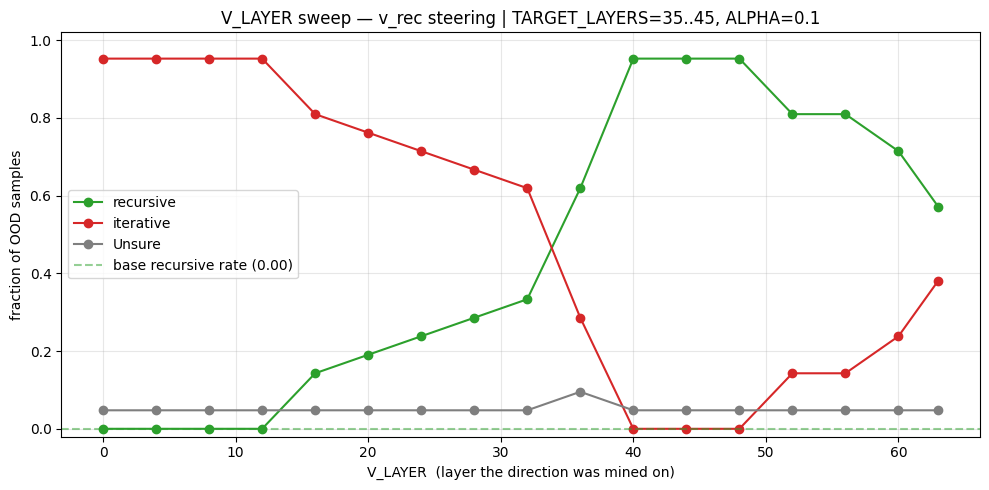

Saved /disk/u/arnab/Codes/Projects/goals/results/recursion_direction/Qwen2.5-Coder-32B-Instruct/figures/v_layer_sweep__T35-45__a0.1.png


In [34]:
# ------- Summary plot: recursive-rate per V_LAYER -------
rec_rate, iter_rate, unsure_rate = [], [], []
for L in V_LAYERS_SWEEP:
    labels = [r["label"] for r in sweep_by_layer[L]]
    n = len(labels)
    rec_rate.append(   sum(l == "recursive" for l in labels) / n)
    iter_rate.append(  sum(l == "iterative" for l in labels) / n)
    unsure_rate.append(sum(l == "Unsure"    for l in labels) / n)

base_rec_rate = sum(l == "recursive" for l in base_labels.values()) / len(base_labels)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(V_LAYERS_SWEEP, rec_rate,    "o-", color="tab:green", label="recursive")
ax.plot(V_LAYERS_SWEEP, iter_rate,   "o-", color="tab:red",   label="iterative")
ax.plot(V_LAYERS_SWEEP, unsure_rate, "o-", color="tab:gray",  label="Unsure")
ax.axhline(base_rec_rate, color="tab:green", ls="--", alpha=0.5,
           label=f"base recursive rate ({base_rec_rate:.2f})")
ax.set_xlabel("V_LAYER  (layer the direction was mined on)")
ax.set_ylabel("fraction of OOD samples")
ax.set_ylim(-0.02, 1.02)
ax.set_title(
    f"V_LAYER sweep — v_rec steering | "
    f"TARGET_LAYERS={TARGET_LAYERS[0]}..{TARGET_LAYERS[-1]}, ALPHA={ALPHA}"
)
ax.legend(loc="best")
ax.grid(alpha=0.3)
plt.tight_layout()

fig_dir = Path(env_utils.DEFAULT_RESULTS_DIR) / "recursion_direction" / mt.name.split("/")[-1] / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
fig_path = fig_dir / f"v_layer_sweep__T{TARGET_LAYERS[0]}-{TARGET_LAYERS[-1]}__a{ALPHA}.png"
plt.savefig(fig_path, dpi=140, bbox_inches="tight")
plt.show()
print(f"Saved {fig_path}")

In [45]:
from src.functional import logit_lens

print(f"{V_LAYER=}")
v_rec = [row for row in sweep_rows if row["layer"] == V_LAYER][0]["v"]

logit_lens(mt = mt, h = 5 * v_rec.to(mt.dtype).to(mt.device), k = 10)

V_LAYER=48


[PredictedToken(token='recursive', prob=0.431640625, logit=22.375, token_id=49512, metadata=None),
 PredictedToken(token='递', prob=0.26171875, logit=21.875, token_id=100520, metadata=None),
 PredictedToken(token='_recursive', prob=0.1591796875, logit=21.375, token_id=66242, metadata=None),
 PredictedToken(token=' recurs', prob=0.05859375, logit=20.375, token_id=24724, metadata=None),
 PredictedToken(token='遞', prob=0.03125, logit=19.75, token_id=119063, metadata=None),
 PredictedToken(token=' recursively', prob=0.027587890625, logit=19.625, token_id=52847, metadata=None),
 PredictedToken(token='Recursive', prob=0.006988525390625, logit=18.25, token_id=78542, metadata=None),
 PredictedToken(token=' Recursive', prob=0.00543212890625, logit=18.0, token_id=85896, metadata=None),
 PredictedToken(token=' recursive', prob=0.0037384033203125, logit=17.625, token_id=30819, metadata=None),
 PredictedToken(token=' recursion', prob=0.0022735595703125, logit=17.125, token_id=50262, metadata=None)]

## 12. Baseline — `v_approx` (weighted top-k `lm_head` rows)

The previous lm-head baseline (`v_lm_head`) used the single row for the literal token `"recursive"`. That direction had insufficient steering power even though `logit_lens(v_rec)` decodes literally to `"recursive"`.

This baseline broadens the bet: pick the top-k tokens by their lm-head affinity with `v_rec`, take their (unit-normalized) lm-head rows, and learn a **weighted combination** that best approximates `v_rec`.

**Setup**
- $k=100$.
- $d_i$ = unit-normalized lm_head row of the $i$-th top token.
- Optimize affine weights $a \in \mathbb{R}^k$ (signs unrestricted) with $\sum_i a_i = 1$.
- Objective: $\min_a \| v_\text{rec} - \sum_i a_i d_i \|^2$ — pure MSE; constraint enforced via reparameterization $a = x - \bar{x} + 1/k$ (differentiable, exact).

If `v_approx` works while `v_lm_head` did not, the takeaway is that the recursion direction lives in the lm-head subspace — just not on any single row.

In [46]:
from src.functional import logit_lens
from baukit import get_module

# ─── 1. top-k tokens by affinity with v_rec ───────────────────────────────────
TOP_K = 100
v_target = v_rec.to(torch.float32).to("cpu")
ll = logit_lens(mt=mt, h=v_rec.to(mt.dtype).to(mt.device), k=TOP_K)
top_token_ids = [t.token_id for t in ll]
print(f"top-10 tokens by lm_head affinity with v_rec: {[ll[i].token for i in range(10)]}")

# ─── 2. lm_head rows, unit-normalized ─────────────────────────────────────────
_lm_head_mod = get_module(mt._model, mt.lm_head_name)
D = _lm_head_mod.weight[top_token_ids].detach().to("cpu", torch.float32)  # (k, n_embd)
D = D / (D.norm(dim=-1, keepdim=True) + 1e-9)
print(f"D shape: {tuple(D.shape)}  (each row unit-norm)")

# ─── 3. Optimize a — sum(a) ≈ 1 as a soft penalty (relaxed from hard) ─────────
# Hard reparameterization (a = x - x.mean() + 1/k) gave cos≈0.3 — the simplex
# constraint was too restrictive. Drop it; enforce sum(a)=1 via a quadratic
# penalty. LAMBDA_SUM controls how tightly. Set LAMBDA_SUM=0 to drop the
# constraint entirely (pure least-squares fit).
N_STEPS = 3000
LR = 5e-3
LAMBDA_SUM = 1e-2   # tune ↑ for stricter sum=1, ↓ for closer fit

x = torch.full((TOP_K,), 1.0 / TOP_K, requires_grad=True)  # init at uniform
opt = torch.optim.Adam([x], lr=LR)

for step in range(N_STEPS):
    a = x
    v_approx = a @ D
    fit_loss    = ((v_target - v_approx) ** 2).sum()
    sum_penalty = (a.sum() - 1.0) ** 2
    loss = fit_loss + LAMBDA_SUM * sum_penalty
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 500 == 0 or step == N_STEPS - 1:
        with torch.no_grad():
            cos = torch.nn.functional.cosine_similarity(v_target, v_approx, dim=0).item()
            print(f"  step {step:5d}  fit={fit_loss.item():.4f}  "
                  f"sum_pen={sum_penalty.item():.4f}  "
                  f"sum(a)={a.sum().item():+.4f}  cos={cos:.4f}")

with torch.no_grad():
    a_final = x.detach()
    v_approx = (a_final @ D).detach()

print(f"\nfinal:")
print(f"  ||v_rec||             = {v_target.norm().item():.4f}")
print(f"  ||v_approx||          = {v_approx.norm().item():.4f}")
print(f"  ||v_rec - v_approx||  = {(v_target - v_approx).norm().item():.4f}")
print(f"  cos(v_rec, v_approx)  = {torch.nn.functional.cosine_similarity(v_target, v_approx, dim=0).item():.4f}")
print(f"  sum(a)                = {a_final.sum().item():+.6f}   (LAMBDA_SUM={LAMBDA_SUM})")
print(f"  min(a)={a_final.min().item():+.4f}   max(a)={a_final.max().item():+.4f}")

print(f"\ntop 15 tokens by |a|:")
top_w = a_final.abs().argsort(descending=True)[:15]
for i in top_w.tolist():
    print(f"  a={a_final[i].item():+.4f}   token={ll[i].token!r}")


top-10 tokens by lm_head affinity with v_rec: ['recursive', '递', '_recursive', ' recurs', ' recursively', '遞', 'Recursive', ' Recursive', ' recursive', ' recursion']
D shape: (100, 5120)  (each row unit-norm)
  step     0  fit=0.9476  sum_pen=0.0000  sum(a)=+0.9300  cos=0.2335
  step   500  fit=0.9046  sum_pen=0.1201  sum(a)=+1.3465  cos=0.3093
  step  1000  fit=0.9046  sum_pen=0.1201  sum(a)=+1.3465  cos=0.3093
  step  1500  fit=0.9046  sum_pen=0.1201  sum(a)=+1.3465  cos=0.3093
  step  2000  fit=0.9046  sum_pen=0.1201  sum(a)=+1.3465  cos=0.3093
  step  2500  fit=0.9046  sum_pen=0.1182  sum(a)=+1.3426  cos=0.3093
  step  2999  fit=0.9046  sum_pen=0.1201  sum(a)=+1.3465  cos=0.3093

final:
  ||v_rec||             = 1.0000
  ||v_approx||          = 0.2934
  ||v_rec - v_approx||  = 0.9511
  cos(v_rec, v_approx)  = 0.3093
  sum(a)                = +1.346539   (LAMBDA_SUM=0.01)
  min(a)=-0.0428   max(a)=+0.0974

top 15 tokens by |a|:
  a=+0.0974   token=' tree'
  a=+0.0573   token=' trees

In [47]:
# ─── 4. Run causal test on ood_samples using v_approx ────────────────────────
HAS_CACHE = (
    "ood_results" in globals()
    and "prompts_by_idx" in globals()
    and "inputs_by_idx" in globals()
    and "layerwise_h_means_by_idx" in globals()
    and "base_by_idx" in globals()
)
print(f"HAS_CACHE (base + v_rec from prior sweep)={HAS_CACHE}")

v_approx_results: list[dict] = []
for i, sample in enumerate(tqdm(ood_samples, desc="v_approx OOD")):
    if HAS_CACHE:
        inputs = inputs_by_idx[i]
        h_mean = layerwise_h_means_by_idx[i]
    else:
        prompt = get_prompt(sample, mt)
        inputs = prepare_input(prompts=prompt, tokenizer=mt)
        src_hs_s = get_hs(
            mt=mt, input=prompt,
            locations=[(layer, t) for layer in mt.layer_names for t in src_token_range],
            return_dict=True,
        )
        h_mean = {
            layer: torch.stack(
                [src_hs_s[(layer, t)].to(torch.float32) for t in src_token_range], dim=0
            ).mean(dim=0)
            for layer in mt.layer_names
        }
    completion = _steer_additive(v_approx, inputs, h_mean)
    label = _label_strategy_cpp(sample.code + completion, sample.function_name)
    v_approx_results.append({
        "function": sample.function_name,
        "completion": completion,
        "label": label,
    })

# ─── 5. Print table: base + v_rec (if cached) + v_approx ─────────────────────
_LABEL_STYLE = {"recursive": "sea_green3", "iterative": "salmon1", "Unsure": "grey50"}

title = (
    f"v_approx (weighted top-{TOP_K} lm_head rows) — OOD causal test  | "
    f"V_LAYER={V_LAYER}, TARGET_LAYERS={TARGET_LAYERS[0]}..{TARGET_LAYERS[-1]}, ALPHA={ALPHA}"
)
table = Table(title=title, show_lines=True, expand=True)
table.add_column("function", style="bright_white", no_wrap=True, min_width=14, max_width=22)
table.add_column("base", overflow="fold", ratio=1, min_width=28)
if HAS_CACHE:
    table.add_column("v_rec", overflow="fold", ratio=1, min_width=28)
table.add_column("v_approx", overflow="fold", ratio=1, min_width=28)

# Tally for a quick summary line.
counts = {"base": {}, "v_rec": {}, "v_approx": {}}
def _bump(k, lab): counts[k][lab] = counts[k].get(lab, 0) + 1

for i, sample in enumerate(ood_samples):
    prompt = prompts_by_idx[i] if HAS_CACHE else get_prompt(sample, mt)
    prompt_stub = prompt[prompt.index("<code>\n"):]

    if HAS_CACHE:
        base_text = base_by_idx[i]
        base_label = (
            base_labels[i] if "base_labels" in globals()
            else _label_strategy_cpp(sample.code + base_text, sample.function_name)
        )
    else:
        base_text = greedy_continue(mt, **inputs, max_new_tokens=256)
        base_label = _label_strategy_cpp(sample.code + base_text, sample.function_name)
    _bump("base", base_label)

    row_cells = [f"[bold]{sample.function_name}[/bold]"]
    bt = Text(); bt.append(prompt_stub, style="white"); bt.append(base_text, style=_LABEL_STYLE[base_label])
    row_cells.append(bt)

    if HAS_CACHE:
        v_rec_text = ood_results[i]["v_rec"]
        v_rec_label = _label_strategy_cpp(sample.code + v_rec_text, sample.function_name)
        _bump("v_rec", v_rec_label)
        vt = Text(); vt.append(prompt_stub, style="white"); vt.append(v_rec_text, style=_LABEL_STYLE[v_rec_label])
        row_cells.append(vt)

    ap_text = v_approx_results[i]["completion"]
    ap_lab  = v_approx_results[i]["label"]
    _bump("v_approx", ap_lab)
    apt = Text(); apt.append(prompt_stub, style="white"); apt.append(ap_text, style=_LABEL_STYLE[ap_lab])
    row_cells.append(apt)

    table.add_row(*row_cells)

ncols = 3 + (1 if HAS_CACHE else 0)
console_w = 60 + 52 * (ncols - 1)
out_console = Console(width=console_w, highlight=False, record=True)
out_console.print(table)

# Summary tallies.
print("\nlabel tallies (n_samples = {}):".format(len(ood_samples)))
keys = ["base"] + (["v_rec"] if HAS_CACHE else []) + ["v_approx"]
labs = ["recursive", "iterative", "Unsure"]
hdr = f"  {'':>10s} " + "  ".join(f"{l:>10s}" for l in labs)
print(hdr)
for k in keys:
    line = f"  {k:>10s} " + "  ".join(f"{counts[k].get(l, 0):>10d}" for l in labs)
    print(line)

# Save the table.
out_dir = Path(env_utils.DEFAULT_RESULTS_DIR) / "recursion_direction" / mt.name.split("/")[-1]
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / f"ood_causal_test_v_approx__k{TOP_K}__V{V_LAYER}__T{TARGET_LAYERS[0]}-{TARGET_LAYERS[-1]}__a{ALPHA}.html"
out_console.save_html(str(out_path), inline_styles=True, theme=VSCODE_DARK)
print(f"\nSaved HTML -> {out_path}")


HAS_CACHE (base + v_rec from prior sweep)=True


v_approx OOD:   0%|          | 0/20 [00:00<?, ?it/s]

                                                       v_approx (weighted top-100 lm_head rows) — OOD causal test  | V_LAYER=48, TARGET_LAYERS=35..45, ALPHA=0.1                                                        
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ function          ┃ base                                                           ┃ v_rec                                                          ┃ v_approx                                                       ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ count_occurrences │ <code>                                                         │ <code>                                                         │ <code>                                                         │
│                   │ int count_occurrences(std::vector<int>& numbers, int target) { │ int count_occurrences(std::vector<int>& numbers, int target) { │ int count_occurrences(std::vector<int>& numbers, int target) { │
│                   │     int count = 0;                                             │     if (numbers.empty()) return 0;                             │     if (numbers.empty()) return 0;                             │
│                   │     for (int i = 0; i < numbers.size(); i++) {                 │     if (numbers[0] == target) return 1 +                       │     int count = 0;                                             │
│                   │         if (numbers[i] == target) {                            │ count_occurrences(numbers.substr(1), target);                  │     for (int i = 0; i < numbers.size(); ++i) {                 │
│                   │             count++;                                           │     else return count_occurrences(numbers.substr(1), target);  │         if (numbers[i] == target) {                            │
│                   │         }                                                      │ }                                                              │             count += 1;                                        │
│                   │     }                                                          │ </code>                                                        │         }                                                      │
│                   │     return count;                                              │                                                                │         count += count_occurrences(numbers[i], target);        │
│                   │ }                                                              │ Note: The `substr` method is not a standard method for         │     }                                                          │
│                   │ </code>                                                        │ `std::vector`. This is a simplified version to demonstrate the │     return count;                                              │
│                   │                                                                │ concept. In actual implementation, it should be:               │ }                                                              │
│                   │                                                                │ <code>                                                         │ </code>                                                        │
│                   │                                                                │ int count_occurrences(std::vector<int>& numbers, int target) { │                                                                │
│                   │                                                                │     if 


label tallies (n_samples = 20):
              recursive   iterative      Unsure
        base          0          19           1
       v_rec         19           0           1
    v_approx         10           9           1

Saved HTML -> /disk/u/arnab/Codes/Projects/goals/results/recursion_direction/Qwen2.5-Coder-32B-Instruct/ood_causal_test_v_approx__k100__V48__T35-45__a0.1.html
